# [17.4] Training Dynamics Across Architectures (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter17_training_dynamics/exercises/part4_cross_architecture_dynamics/17.4_Training_Dynamics_Across_Architectures_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter17_training_dynamics/exercises/part4_cross_architecture_dynamics/17.4_Training_Dynamics_Across_Architectures_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-12.png" width="350">

# Introduction

By the end of this notebook, you will have shown that representation rotation can preserve CKA, rank and task information while anisotropic scaling and example misalignment change the comparison, using a finite token-memory task and shuffled-label controls.

A sequence has six binary tokens. The downstream question is always: **what was the first token?** An autoregressive transformer, a selective state-space model, a masked-token model and a joint-embedding predictor could all represent the answer, but their training losses do not mean the same thing. If one gets to loss .1 sooner, does it learn memory faster?

Before running that expensive comparison, we need implementations and controls that cannot be fooled by units, a changed feature basis, mismatched example order or an ever-larger probe. You will build the core causal attention and selective recurrence calculations, the two different objective reductions, and the checkpoint metrics. Then you will inspect fixed **constructed representation checkpoints** of the same task. Their coordinate is a chosen signal amplitude; it is not measured training time.

A full study would call for training small AR transformer, Mamba, masked-diffusion LM and JEPA models on a common suite. That full four-architecture experiment is pending. The study edition supplies runnable metric and objective tooling without mislabeling a diagonal recurrence as native Mamba, a masked CE slice as a full diffusion ELBO, or latent MSE as a full JEPA training recipe.

Prerequisites: attention, recurrence, SVD, least squares and [11.1] representation geometry. Allow 100–140 minutes. All default examples are deterministic CPU arrays with no downloads.

## Content & Learning Objectives

### 1️⃣ Same task, different computations

> ##### Learning Objectives
>
> - Implement causal attention and a diagonal selective state-space recurrence on the same sequence.

### 2️⃣ Different objectives, different denominators

> ##### Learning Objectives
>
> - Compute masked-token and latent-prediction losses and keep their units separate.

### 3️⃣ Compare representations without confusing coordinates

> ##### Learning Objectives
>
> - Implement centered linear CKA, singular-value effective rank and a frozen linear probe with controls.

### 4️⃣ Build a fair checkpoint comparison

> ##### Learning Objectives
>
> - Align example identities and budget axes, then distinguish analytic checkpoint geometry from native training evidence.

## Setup code

Use the repository environment. This study edition needs only NumPy and Matplotlib, runs on CPU, and downloads nothing.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
chapter = "chapter17_training_dynamics"
section = "part4_cross_architecture_dynamics"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))
import part4_cross_architecture_dynamics.tests as tests
import part4_cross_architecture_dynamics.utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Same task, different computations

> ##### Learning Objectives
>
> - Implement causal attention and a diagonal selective state-space recurrence on the same sequence.

For a single sequence, queries and keys have shape $[T,d_k]$ and values $[T,d_v]$. Causal attention computes $\mathrm{softmax}(QK^\top/\sqrt{d_k}+M)V$, where future entries of $M$ are $-\infty$. This gives the computation an AR model can use, but training still needs embeddings, residual blocks, normalization, readout and an optimizer.

A selective SSM instead updates a state. For a diagonal one-state-per-channel system, $h_t=\exp(\Delta_t A)h_{t-1}+B_t u_t(\exp(\Delta_t A)-1)/A$ and $y_t=C_t h_t$. Handle $A=0$ by its limit $\Delta_t$. Here $\Delta,B,C$ are input-dependent arrays supplied by the caller. This exact zero-order-hold recurrence teaches discretization and selectivity. Full Mamba adds learned projections, multiple states, convolution/gating and its hardware-aware scan; those are not secretly supplied by our helper.

### Exercise - implement `causal_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return attention output [T,dv] from Q,K,V. Require matching sequence lengths; mask future positions before row normalization.

In [2]:
def causal_attention(q, k, v):
    scores=q@k.T/np.sqrt(q.shape[-1])
    scores=np.where(np.tril(np.ones(scores.shape,dtype=bool)),scores,-np.inf)
    weights=np.exp(scores-scores.max(axis=-1,keepdims=True))
    weights/=weights.sum(axis=-1,keepdims=True)
    return weights@v


tests.test_causal_attention(causal_attention)

All tests in test_causal_attention passed!


<details><summary>Hint</summary>

Zero queries and keys must produce running means; a future value must never affect an earlier output.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Uniform causal attention on [1,3,8] returns [1,2,4].</pre>

</details>

### Exercise - implement `selective_scan`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return outputs [T,d] for supplied u, delta, B, C of shape [T,d] and diagonal A [d]. Start state zero; use stable expm1 and the exact A=0 limit. This is a small scalar-channel SSM, not the full Mamba block.

In [3]:
def selective_scan(u, delta, a, b, c):
    state=np.zeros(u.shape[1]);outputs=[]
    for t in range(len(u)):
        decay=np.exp(delta[t]*a)
        integral=np.empty_like(decay)
        nonzero=a!=0
        integral[nonzero]=np.expm1(delta[t,nonzero]*a[nonzero])/a[nonzero]
        integral[~nonzero]=delta[t,~nonzero]
        state=decay*state+integral*b[t]*u[t]
        outputs.append(c[t]*state)
    return np.array(outputs)


tests.test_selective_scan(selective_scan)

All tests in test_selective_scan passed!


<details><summary>Hint</summary>

Use the discretization integral, not delta*B unless taking that separately labeled approximation.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">A=0, Δ=B=C=1 integrates [1,2,3] to [1,3,6].</pre>

</details>

position token causal-mean leaky-scan selected-first-memory
0 +1.000 +1.000 +0.632 +1.000
1 -1.000 +0.000 -0.400 +1.000
2 +1.000 +0.333 +0.485 +1.000
3 +1.000 +0.500 +0.811 +1.000
4 -1.000 +0.200 -0.334 +1.000
5 -1.000 +0.000 -0.755 +1.000


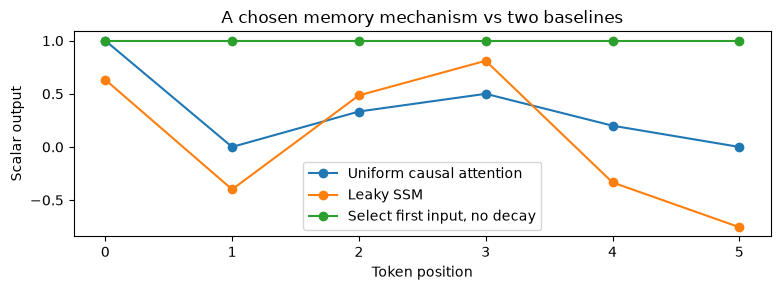

In [4]:
sequence=np.array([[1.],[-1.],[1.],[1.],[-1.],[-1.]])
q=np.zeros((len(sequence),1))
attention_output=causal_attention(q,q,sequence).ravel()
delta=np.ones_like(sequence); b=np.ones_like(sequence); c=np.ones_like(sequence)
scan_output=selective_scan(sequence,delta,np.array([-1.]),b,c).ravel()
selected_b=np.zeros_like(sequence);selected_b[0]=1
memory_output=selective_scan(sequence,delta,np.array([0.]),selected_b,c).ravel()
print("position token causal-mean leaky-scan selected-first-memory")
for i,row in enumerate(zip(sequence.ravel(),attention_output,scan_output,memory_output)):
    print(i,*[f"{v:+.3f}" for v in row])
fig,ax=plt.subplots(figsize=(8,3))
for vals,label in [(attention_output,"Uniform causal attention"),(scan_output,"Leaky SSM"),(memory_output,"Select first input, no decay")]:
    ax.plot(np.arange(6),vals,"o-",label=label)
ax.set(xlabel="Token position",ylabel="Scalar output",title="A chosen memory mechanism vs two baselines")
ax.legend();utils.finish_figure(fig)

<details><summary>Help - how should I interpret this?</summary>

The selected recurrence remembers the first token because we explicitly set its input gate at position zero and chose no decay. Uniform attention averages later distractors; the leaky recurrence discounts early information. These are chosen computations, not evidence that any trained architecture succeeds or fails on the task.

</details>

## Summary of 1️⃣

Both attention and recurrence can carry sequence information. Their capacity does not by itself establish learning speed, accuracy or compute efficiency.

# 2️⃣ Different objectives, different denominators

> ##### Learning Objectives
>
> - Compute masked-token and latent-prediction losses and keep their units separate.

AR negative log likelihood averages $-\log p(x_{t+1}\mid x_{\le t})$ over scored destinations. A masked-token objective averages negative log probability over **masked target sites**, with corruption schedule and time weighting declared separately. We implement that per-slice reduction; it is not the complete masked diffusion likelihood bound.

JEPA-style prediction compares a context prediction to target **representations**, rather than predicting token IDs. A simple squared-error slice averages across batch, target positions and feature dimensions. Its numerical scale depends on representation scaling and normalization. A real JEPA system needs a target encoder and a specified stop-gradient/EMA update to prevent trivial joint collapse; computing an array loss does not implement those safeguards.

Never put these raw losses on one shared “capability” axis. They answer different questions and use different denominators. Use a common frozen downstream task as a separate measurement.

### Exercise - implement `token_nll`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute per-site [batch,T] negative log probability from [batch,T,vocab] logits and integer targets [batch,T], using stable log-sum-exp. Alignment is the caller’s responsibility.

In [5]:
def token_nll(logits, targets):
    m=logits.max(axis=-1,keepdims=True)
    log_z=m[...,0]+np.log(np.exp(logits-m).sum(axis=-1))
    chosen=np.take_along_axis(logits,targets[...,None],axis=-1)[...,0]
    return log_z-chosen


tests.test_token_nll(token_nll)

All tests in test_token_nll passed!


<details><summary>Hint</summary>

Keep both batch and token dimensions until a later objective defines its mask and denominator.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Targets with probabilities .75 and .5 give [.287682,.693147].</pre>

</details>

### Exercise - implement `masked_token_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Average supplied per-site losses only where a boolean mask is true. Raise on an empty mask. This is one corruption-time slice, without diffusion time weighting.

In [6]:
def masked_token_loss(losses, mask):
    if not np.any(mask):
        raise ValueError("No masked targets")
    return float(np.mean(losses[mask]))


tests.test_masked_token_loss(masked_token_loss)

All tests in test_masked_token_loss passed!


<details><summary>Hint</summary>

Do not divide by the total number of tokens, which changes with mask rate.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Losses [1,100,3], mask [true,false,true] give 2, not 4/3.</pre>

</details>

### Exercise - implement `latent_prediction_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return mean squared error between equally shaped prediction and fixed target arrays. The target array is an already frozen snapshot; a native autograd implementation must separately detach/EMA its target encoder.

In [7]:
def latent_prediction_loss(prediction, target):
    if prediction.shape != target.shape:
        raise ValueError("Prediction/target shape mismatch")
    return float(np.mean((prediction-target)**2))


tests.test_latent_prediction_loss(latent_prediction_loss)

All tests in test_latent_prediction_loss passed!


<details><summary>Hint</summary>

The reduction includes feature dimensions, unlike token CE.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Prediction [1,3] vs target [0,1] has MSE 2.5; both-zero collapse also has loss 0.</pre>

</details>

In [8]:
site_losses=np.array([[1.,100.,3.]])
mask=np.array([[True,False,True]])
print("masked slice loss",masked_token_loss(site_losses,mask))
print("latent loss",latent_prediction_loss(np.array([[1.,3.]]),np.array([[0.,1.]])))
print("scaled latent loss",latent_prediction_loss(np.array([[2.,6.]]),np.array([[0.,2.]])))
print("collapsed latent loss",latent_prediction_loss(np.zeros((2,3)),np.zeros((2,3))))

masked slice loss 2.0
latent loss 2.5
scaled latent loss 10.0
collapsed latent loss 0.0


<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">masked slice loss 2.0
latent loss 2.5
scaled latent loss 10.0
collapsed latent loss 0.0</pre>

</details>

The masked loss ignores the unscored 100. Doubling both latent arrays multiplies MSE by four without changing any token prediction. Collapse produces a deceptively good zero reconstruction loss. These are reasons to keep objectives separate and measure task behavior.

## Summary of 2️⃣

You can now detect two unfair comparisons: a denominator changed by mask rate, and a latent objective rescaled by representation magnitude.

# 3️⃣ Compare representations without confusing coordinates

> ##### Learning Objectives
>
> - Implement centered linear CKA, singular-value effective rank and a frozen linear probe with controls.

Linear CKA compares centered representations of the **same examples**. For $X_c,Y_c$ centered over examples,
$$\operatorname{CKA}(X,Y)=\frac{\|X_c^\top Y_c\|_F^2}{\|X_c^\top X_c\|_F\,\|Y_c^\top Y_c\|_F}.$$
It is invariant to orthogonal feature rotations and global rescaling, but not arbitrary anisotropic scaling. If either centered representation is zero, the normalization is undefined: report NaN instead of perfect agreement.

Effective rank is $\exp(-\sum_i p_i\log p_i)$ with $p_i=\sigma_i/\sum_j\sigma_j$ for the singular values of centered activations. We use singular-value mass, **not squared singular-value energy**; those are different valid conventions and must not be silently mixed. Define zero rank for a collapsed representation. Rank measures dimensional spread, not whether that spread contains the answer.

A ridge probe can measure linearly recoverable information: fit on one frozen subset, freeze regularization, then score a separate monitored subset. A probe is a learned readout, not proof that the original model uses the feature. A shuffled TRAIN-label probe is its negative control.

### Exercise - implement `center_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Subtract the column mean from [examples,features]. Preserve the example dimension and input array.

In [9]:
def center_features(x):
    return x-x.mean(axis=0,keepdims=True)


tests.test_center_features(center_features)

All tests in test_center_features passed!


<details><summary>Hint</summary>

Center over examples (axis 0), not within each feature vector.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">[[1,2],[3,6]] centers to [[-1,-2],[1,2]].</pre>

</details>

### Exercise - implement `linear_cka`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute centered linear CKA, allowing different feature widths but requiring the same ordered examples. Return NaN for a zero denominator.

In [10]:
def linear_cka(x, y):
    if len(x)!=len(y):
        raise ValueError("Need same examples")
    x=center_features(x);y=center_features(y)
    den=np.linalg.norm(x.T@x)*np.linalg.norm(y.T@y)
    return float(np.linalg.norm(x.T@y)**2/den) if den else float("nan")


tests.test_linear_cka(linear_cka)

All tests in test_linear_cka passed!


<details><summary>Hint</summary>

The independent test uses centered Gram matrices rather than your feature-space formula.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">A translated orthogonal rotation has CKA 1; a collapsed representation gives NaN.</pre>

</details>

### Exercise - implement `effective_rank`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the entropy effective rank of centered activations using normalized singular values. Ignore zero singular values when taking logs; return 0 for an exactly collapsed representation.

In [11]:
def effective_rank(x):
    s=np.linalg.svd(center_features(x),compute_uv=False)
    if s.sum()==0:
        return 0.0
    p=s[s>0]/s.sum()
    return float(np.exp(-np.sum(p*np.log(p))))


tests.test_effective_rank(effective_rank)

All tests in test_effective_rank passed!


<details><summary>Hint</summary>

Do not square singular values; the convention in this notebook is nuclear-mass entropy.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Two equal nonzero singular values give rank 2; one gives 1; collapse gives 0.</pre>

</details>

### Exercise - implement `fit_ridge_probe`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit a centered ridge linear readout to signed targets with an unpenalized intercept. Return weights [d] and scalar bias. Require positive ridge regularization.

In [12]:
def fit_ridge_probe(x, targets, ridge=.1):
    if ridge<=0:
        raise ValueError("Use positive ridge")
    mean_x=x.mean(axis=0);mean_y=targets.mean()
    xc=x-mean_x;yc=targets-mean_y
    w=np.linalg.solve(xc.T@xc+ridge*np.eye(x.shape[1]),xc.T@yc)
    return w,float(mean_y-mean_x@w)


tests.test_fit_ridge_probe(fit_ridge_probe)

All tests in test_fit_ridge_probe passed!


<details><summary>Hint</summary>

An intercept is not a feature that should be shrunk by ridge.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">X=[4,6], labels[-1,1], ridge2 gives w=.5,b=-2.5.</pre>

</details>

### Exercise - implement `probe_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Evaluate a frozen readout on features and signed targets. A zero score is counted incorrect, using target*score >0.

In [13]:
def probe_accuracy(x, targets, weights, bias):
    return float(np.mean(targets*(x@weights+bias)>0))


tests.test_probe_accuracy(probe_accuracy)

All tests in test_probe_accuracy passed!


<details><summary>Hint</summary>

Keep the scoring tie rule fixed across architectures and checkpoints.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Two correct nonzero margins and one tie give accuracy 2/3.</pre>

</details>

If we rotate every feature vector by the same orthogonal matrix, will CKA or effective rank change? If we permute example rows at only one checkpoint, what breaks? Will a small-amplitude answer feature reduce probe accuracy even when the feature is mathematically present? Record values or directions before inspecting the output.

g rank CKA_rotation CKA_wrong_rows DEV_probe shuffled_TRAIN_probe
0.0000 3.0000 1.0000 0.0742 0.3750 0.4375
0.0100 3.0564 1.0000 0.0742 0.3750 0.4375
0.0500 3.2035 1.0000 0.0744 1.0000 0.4375
0.1000 3.3390 1.0000 0.0748 1.0000 0.4375
0.3000 3.6817 1.0000 0.0792 1.0000 0.4375
1.0000 4.0000 1.0000 0.0996 1.0000 0.4375


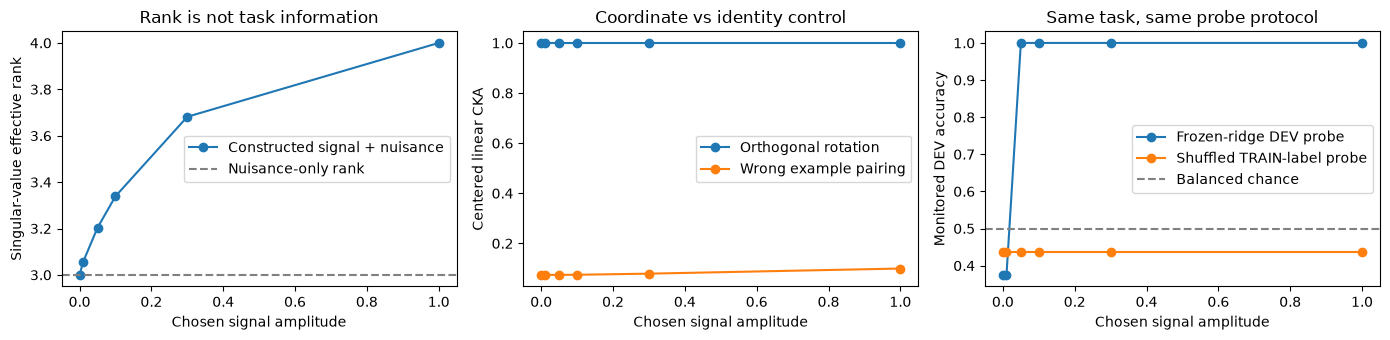

In [14]:
sequences=np.array(list(product([-1.,1.],repeat=6)))
labels=sequences[:,0]
noise=sequences[:,1:4]
ids=["".join("1" if x>0 else "0" for x in row) for row in sequences]
rng=np.random.default_rng(17)
order=rng.permutation(len(sequences));train=order[:32];dev=order[32:]
# These are distinct finite sequences with overlapping abstract feature combinations.
# TRAIN fits probes; DEV is monitored throughout; there is no untouched TEST.
q,_=np.linalg.qr(rng.normal(size=(4,4)))
row_shuffle=rng.permutation(len(sequences))
shuffled_train_labels=rng.permutation(labels[train])
strengths=np.array([0.,.01,.05,.1,.3,1.])
representations=[np.column_stack([g*labels,noise]) for g in strengths]
rank=[];cka=[];cka_wrong=[];acc=[];acc_control=[]
for rep in representations:
    rank.append(effective_rank(rep));cka.append(linear_cka(rep,rep@q))
    cka_wrong.append(linear_cka(rep,(rep@q)[row_shuffle]))
    w,bias=fit_ridge_probe(rep[train],labels[train],ridge=.1)
    wc,bc=fit_ridge_probe(rep[train],shuffled_train_labels,ridge=.1)
    acc.append(probe_accuracy(rep[dev],labels[dev],w,bias))
    acc_control.append(probe_accuracy(rep[dev],labels[dev],wc,bc))
print("g rank CKA_rotation CKA_wrong_rows DEV_probe shuffled_TRAIN_probe")
for row in zip(strengths,rank,cka,cka_wrong,acc,acc_control):
    print(" ".join(f"{x:.4f}" for x in row))
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
axes[0].plot(strengths,rank,"o-",label="Constructed signal + nuisance")
axes[0].axhline(effective_rank(noise),ls="--",color="gray",label="Nuisance-only rank")
axes[0].set(xlabel="Chosen signal amplitude",ylabel="Singular-value effective rank",title="Rank is not task information");axes[0].legend()
axes[1].plot(strengths,cka,"o-",label="Orthogonal rotation")
axes[1].plot(strengths,cka_wrong,"o-",label="Wrong example pairing")
axes[1].set(xlabel="Chosen signal amplitude",ylabel="Centered linear CKA",title="Coordinate vs identity control");axes[1].legend()
axes[2].plot(strengths,acc,"o-",label="Frozen-ridge DEV probe")
axes[2].plot(strengths,acc_control,"o-",label="Shuffled TRAIN-label probe")
axes[2].axhline(.5,ls="--",color="gray",label="Balanced chance")
axes[2].set(xlabel="Chosen signal amplitude",ylabel="Monitored DEV accuracy",title="Same task, same probe protocol");axes[2].legend()
utils.finish_figure(fig)

<details><summary>Help - how should I interpret this?</summary>

The orthogonal rotation preserves CKA even though individual feature coordinates change completely. Row misalignment destroys the intended comparison. Nuisance features already give rank three before the answer channel appears, so high rank alone is not success. With positive ridge, finite-amplitude signal competes with spurious finite-sample nuisance correlations; information present in principle is not the same as perfect performance by a fixed regularized probe. DEV is intentionally viewed across the whole curve and cannot later be called untouched TEST.

</details>

## Summary of 3️⃣

A representation comparison needs row identity, a declared rank convention and a frozen probe. These metrics measure different aspects of change; agreement is evidence to interpret, not a universal equivalence.

# 4️⃣ Build a fair checkpoint comparison

> ##### Learning Objectives
>
> - Align example identities and budget axes, then distinguish analytic checkpoint geometry from native training evidence.

Native architectures need comparable *task access* and *budgets*. AR sees a prefix; a bidirectional masked model may see both sides of a gap. To compare first-token memory, give every evaluated readout exactly the same available context. JEPA predicts latent targets, so fit the same downstream probe under the same training-role rules instead of comparing its raw loss with token CE.

Plot checkpoint metrics against optimizer steps **and** processed tokens, then add measured device time and a declared compute estimate if available. A step that evaluates many corruption times or target blocks differs from a single AR minibatch. Cumulative tokens alone do not establish matched FLOPs or walltime. The next exercise makes that arithmetic visible without inventing hardware speed measurements.

### Exercise - implement `cumulative_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Convert per-checkpoint-interval updates, global batch size and sequence length into cumulative processed tokens. Use the actual global batch after accumulation. Include repeated token processing in multiple objective passes.

In [15]:
def cumulative_tokens(updates, batch_size, sequence_length, passes=1):
    if batch_size<=0 or sequence_length<=0 or passes<=0 or np.any(np.asarray(updates)<0):
        raise ValueError("Invalid budget count")
    return np.cumsum(np.asarray(updates))*batch_size*sequence_length*passes


tests.test_cumulative_tokens(cumulative_tokens)

All tests in test_cumulative_tokens passed!


<details><summary>Hint</summary>

The input counts are interval updates, not already cumulative steps.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">[2,3] updates with batch4,length8 gives [64,160] processed tokens; two passes doubles it.</pre>

</details>

### Exercise - implement `align_examples`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Reorder candidate activations into reference ID order. Reject duplicates or missing/extra IDs. This is explicit alignment, unlike blindly sorting both data arrays.

In [16]:
def align_examples(reference_ids, candidate_ids, candidate):
    if len(set(reference_ids))!=len(reference_ids) or len(set(candidate_ids))!=len(candidate_ids):
        raise ValueError("Example IDs must be unique")
    if set(reference_ids)!=set(candidate_ids) or len(candidate_ids)!=len(candidate):
        raise ValueError("Example identity mismatch")
    positions={eid:i for i,eid in enumerate(candidate_ids)}
    return candidate[[positions[eid] for eid in reference_ids]]


tests.test_align_examples(align_examples)

All tests in test_align_examples passed!


<details><summary>Hint</summary>

Use ID→row indexing, and verify one-to-one identity before reordering.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Candidate rows b=2,a=1 align to [1,2].</pre>

</details>

In [17]:
aligned=align_examples(ids,[ids[i] for i in row_shuffle],(representations[-1]@q)[row_shuffle])
print("aligned rotation CKA",linear_cka(representations[-1],aligned))
print("one-pass token budget",cumulative_tokens([10,10,20],8,6))
print("two-pass token budget",cumulative_tokens([10,10,20],8,6,passes=2))

aligned rotation CKA 1.0
one-pass token budget [ 480  960 1920]
two-pass token budget [ 960 1920 3840]


<details><summary>Reference measurement</summary>

<pre style="white-space: pre-wrap">g=0: rank3, rotated CKA1, wrong-row CKA .0742,
      monitored DEV probe .3750, shuffled TRAIN-label probe .4375
g=.05: rank3.2035, rotated CKA1, wrong-row CKA .0744,
       monitored DEV probe1, shuffled TRAIN-label probe .4375
g=1: rank4, rotated CKA1, wrong-row CKA .0996,
     monitored DEV probe1, shuffled TRAIN-label probe .4375</pre>

</details>

## Try it yourself

Scale only the first feature of the final representation by 10. Predict CKA to the unscaled representation, effective rank and frozen-probe behavior. Then refit the same ridge protocol and compare with its shuffled-label control. This changes geometry anisotropically rather than rotating its coordinate basis.

anisotropic CKA 0.5149227673769059
anisotropic effective rank 2.2116305638083653
refit DEV accuracy 1.0
shuffled-label refit DEV accuracy 0.4375


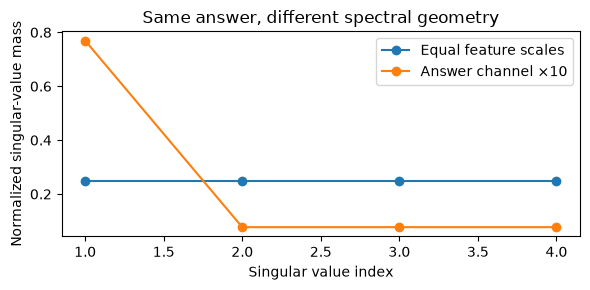

In [18]:
play_scale=10.
base=representations[-1]
changed=base@np.diag([play_scale,1,1,1])
w,bias=fit_ridge_probe(changed[train],labels[train],ridge=.1)
wc,bc=fit_ridge_probe(changed[train],shuffled_train_labels,ridge=.1)
print("anisotropic CKA",linear_cka(base,changed))
print("anisotropic effective rank",effective_rank(changed))
print("refit DEV accuracy",probe_accuracy(changed[dev],labels[dev],w,bias))
print("shuffled-label refit DEV accuracy",probe_accuracy(changed[dev],labels[dev],wc,bc))
fig,ax=plt.subplots(figsize=(6,3))
for rep,label in [(base,"Equal feature scales"),(changed,"Answer channel ×10")]:
    singular=np.linalg.svd(center_features(rep),compute_uv=False)
    ax.plot(np.arange(1,5),singular/singular.sum(),"o-",label=label)
ax.set(xlabel="Singular value index",ylabel="Normalized singular-value mass",title="Same answer, different spectral geometry")
ax.legend();utils.finish_figure(fig)

## Interpreting the result

An orthogonal basis change is a coordinate change; anisotropic scaling changes the relative variance assigned to features. CKA and effective rank respond accordingly, while a correctly refit task probe may still read the same bit. A high representation-similarity score need not imply a shared computation, and a low score need not imply a missing capability.

### The pending native comparison

Freeze a task suite including first-token recall, delayed copying and a distractor change. For each task specify TRAIN, monitored DEV, untouched TEST, exact tokenization and permissible context. Use an actual small AR transformer, a native Mamba implementation, a masked diffusion LM with its time-weighted objective, and a JEPA implementation with context/target encoders and a declared target update. Freeze comparable parameter/budget ranges and a checkpoint cadence. Do not choose architecture-specific best checkpoints on TEST.

Save ordered representations, logits or downstream readout inputs, losses with denominators, step/token/time/compute counters and model hashes. Reuse your visible alignment, CKA, rank and probe functions; include row-shuffle and shuffled TRAIN-label controls at each checkpoint. Compare learning curves over **real** budget axes, with independent seeds and a fixed onset rule. None of the constructed signal curves in this notebook should be copied into that figure as architecture measurements.

**Anomaly hunt:** one model has lower rank and lower raw loss but better memory accuracy. Explain why neither observation is contradictory. Which objective scaling, information-access or collapsed-target control would you inspect first?

## Summary of 4️⃣

You have runnable measurement tools and explicit comparison boundaries. The next scientific step is a separately authorized native training campaign, not a relabeling of these fixtures.

# ☆ Bonus

## Limitations

The recurrence is a diagonal single-state teaching kernel, causal attention is one head without a complete transformer, masked CE is one unweighted time slice, and latent MSE omits target-encoder training. Constructed signal checkpoints are not architecture results. Probe TRAIN and monitored DEV have distinct finite sequences but deliberately overlapping abstract feature combinations; no independent generalization or untouched TEST is claimed. The native four-model training comparison, speed claims and scientific acceptance remain pending.

## Further Reading

- [Kornblith et al.: Similarity of Neural Network Representations Revisited](https://arxiv.org/abs/1905.00414) — CKA and its invariance properties.
- [Gu and Dao: Mamba](https://arxiv.org/abs/2312.00752) — input-dependent selective state spaces and efficient implementation.
- [Sahoo et al.: Simple and Effective Masked Diffusion Language Models](https://arxiv.org/abs/2406.07524) — time-weighted masked diffusion objectives and sampling.
- [Assran et al.: I-JEPA](https://arxiv.org/abs/2301.08243) — context-to-target representation prediction; an image model, not a pretrained text JEPA supplied here.